In [27]:
import sys,os
sys.path.append('../../')
import matplotlib.pyplot as plt
import numpy as np
from utils import makefolder,depths

eps = 1E-7
rcpsize = 14
plt.rcParams['xtick.labelsize']= rcpsize
plt.rcParams['ytick.labelsize']=rcpsize
plt.rcParams['mathtext.fontset'] = 'stix'
plt.rcParams['font.family'] = 'STIXGeneral'
plt.rcParams['font.size'] = rcpsize
plt.rcParams.update({'figure.autolayout': True})
#colors = plt.rcParams['axes.prop_cycle'].by_key()['color']
colors = plt.style.library['ggplot']['axes.prop_cycle'].by_key()['color']
colors = plt.style.library['seaborn-v0_8']['axes.prop_cycle'].by_key()['color']
colors = plt.style.library['seaborn-v0_8-dark-palette']['axes.prop_cycle'].by_key()['color']
from cycler import cycler
plt.rcParams['axes.prop_cycle'] = cycler(color=colors)
# print(plt.rcParams.keys())
#np.set_printoptions(precision=None)
markers = ['*','p','o','h','^']
_linestyles = ['-','--','dotted']
plot_id = 0

In [28]:
batch_shuffle = 0
models = [
          'bert',
          ]

language = 'english'
n_files = 200

mask = 2
min_token_lengths = [40]
k = 10
Nbits = 1
seed_list = np.arange(2,dtype=int) 
n_tokens = 1
take_last = 1

layer_ids=array([ 0,  4,  9, 14, 19, 23])


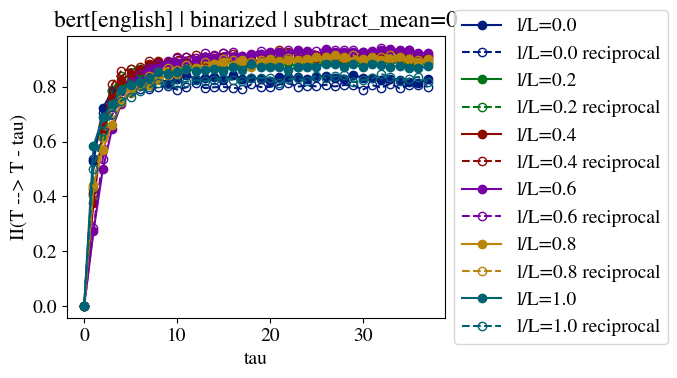

In [29]:


figsfolder = f'results/figs/'
os.makedirs(figsfolder,exist_ok=True)
output_datafolder = f'{figsfolder}data/'
os.makedirs(output_datafolder,exist_ok=True)

subtract_mean_ids = [0]

for min_token_length_id,min_token_length in enumerate(min_token_lengths):
  n_loaded_tokens = min_token_length - mask
  for model_id,model in enumerate(models):
    IIs = np.zeros(shape=(len(seed_list),len(subtract_mean_ids),2,depths[model],n_loaded_tokens))
    for subtract_mean_id,subtract_mean in enumerate(subtract_mean_ids):
      fig,ax = plt.subplots(1,1,
                          figsize=(7,4),
                          # constrained_layout=True,
                          )
      relative_depths = np.array([.001,.2,.4,.6,.8,.999])
      layer_ids = (relative_depths * depths[model]).astype(int)
      print(f'{layer_ids=}')
      for r_id,r in enumerate(relative_depths):
            As = np.zeros(shape=(len(seed_list),depths[model],n_loaded_tokens))
            for seed_id,seed in enumerate(seed_list):
              II_folder = makefolder(base=f'./results/santiago/',
                                        subtract_mean=subtract_mean,
                                        batch_shuffle=batch_shuffle,
                                        take_last=take_last,
                                        modelA=model,
                                        modelB=model,
                                        n_files=n_files,
                                        min_token_length=min_token_length,
                                        languageA=language,
                                        mask=mask,
                                        k=k,
                                        Nbits=Nbits,
                                        seed=seed,
                                        )
              IIs[seed_id,subtract_mean_id,0] = np.load(II_folder + f'n_tokens_{n_tokens}_avg_0_AB.npy')
              IIs[seed_id,subtract_mean_id,1] = np.load(II_folder + f'n_tokens_{n_tokens}_avg_0_BA.npy')
              As[seed_id] = np.load(II_folder + f'n_tokens_{n_tokens}_avg_0_alignment.npy')
              # print(f'{IIs=}')
            ax.plot(range(0,n_loaded_tokens),
                      IIs[:,subtract_mean_id,0,layer_ids[r_id],:].mean(axis=0),
                      linestyle=_linestyles[0],
                      label=f'l/L={round(relative_depths[r_id],1)}',
                      marker='o',
                      color=colors[r_id%len(colors)],)
            ax.plot(range(0,n_loaded_tokens),
                      IIs[:,subtract_mean_id,1,layer_ids[r_id],:].mean(axis=0),
                      linestyle=_linestyles[1],
                      label=f'l/L={round(relative_depths[r_id],1)} reciprocal',
                      marker='o',
                      color=colors[r_id%len(colors)],
                      mfc='none',
                      )
            # np.savetxt(output_datafolder + f'{model}_{language}_layer{layer_ids[r_id]+1}_{min_token_length}_from_last.txt',
            #           IIs[:,0,layer_ids[r_id],:].mean(axis=0))
            # np.savetxt(output_datafolder + f'{model}_{language}_layer{layer_ids[r_id]+1}_{min_token_length}_to_last.txt',
            #           IIs[:,1,layer_ids[r_id],:].mean(axis=0))

 
      ax.set_xlabel('tau')
      ax.set_ylabel('II(T --> T - tau)')
      # ax.set_ylim(.5,1.01)
      my_title = f'{model}[{language}]'

      if Nbits: 
        my_title += f' | binarized | {subtract_mean=}' 
      else: 
        my_title += f' | continuous | {subtract_mean=}'

      ax.set_title(my_title)
      box = ax.get_position()
      ax.set_position([box.x0, box.y0, box.width * 0.8, box.height])
      ax.legend(loc='center left', bbox_to_anchor=(1, 0.5))
      fig.savefig(f'{figsfolder}_{model}_{layer_ids}_future-past-II.pdf',bbox_inches='tight')

IIs.shape=(5, 2, 24, 38)


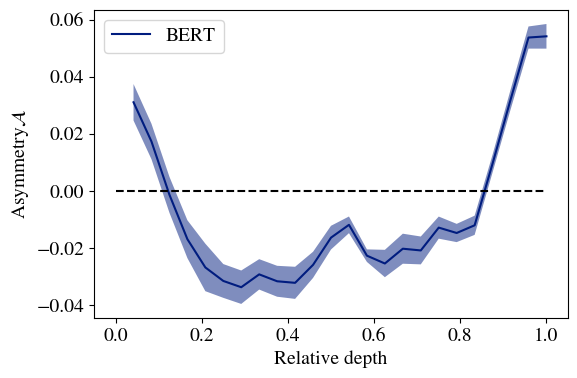

In [33]:
min_token_lengths = [40]
Nbits = 0
seed_list = np.arange(5,dtype=int)
for subtract_mean_id,subtract_mean in enumerate([0]):
  fig,ax = plt.subplots(1,figsize=(6,4))
  for model_id,model in enumerate(models):
    for min_token_length_id,min_token_length in enumerate(min_token_lengths):
          n_loaded_tokens = min_token_length - mask
          IIs = np.zeros(shape=(len(seed_list),2,depths[model],n_loaded_tokens))
          for seed_id,seed in enumerate(seed_list):
            II_folder = makefolder(base=f'./results/santiago/',
                                        subtract_mean=subtract_mean,
                                        batch_shuffle=batch_shuffle,
                                        take_last=take_last,
                                        modelA=model,
                                        modelB=model,
                                        n_files=n_files,
                                        min_token_length=min_token_length,
                                        languageA=language,
                                        mask=mask,
                                        k=k,
                                        Nbits=Nbits,
                                        seed=seed,
                                      )
            IIs[seed_id,0] = np.load(II_folder + f'n_tokens_{n_tokens}_avg_0_AB.npy')
            IIs[seed_id,1] = np.load(II_folder + f'n_tokens_{n_tokens}_avg_0_BA.npy')
            max_tokens = 0 # (n_loaded_tokens+2) // 2
          print(f'{IIs.shape=}')
          # A = IIs[:,0,:,max_tokens:].mean(axis=0).mean(axis=-1) - IIs[:,1,:,max_tokens:].mean(axis=0).mean(axis=-1)
          A = (IIs[:,0,:,max_tokens:] - IIs[:,1,:,max_tokens:]).mean(axis=-1)
          mu = A.mean(axis=0)
          std = A.std(axis=0)
          x = np.arange(1,depths[model]+1)/depths[model]
          ax.plot(x,
                  mu,
                  label=f'BERT',
                  )
          ax.fill_between(x,mu-std,mu+std,alpha=.5)
          # np.savetxt(f'{output_datafolder}asymmetry_layers_{model}_{language}_{min_token_length}.txt',
          # np.array([np.arange(1,depths[model]+1),A]).T)
  # ax.set_ylabel('II(future --> past) - II(past --> future)')
  ax.set_ylabel('Asymmetry' + r'$\mathcal{A}$')  
  ax.set_xlabel('Relative depth')
  # ax.set_title(f'{min_token_length=}')

  my_title = f'{model}[{language}]'

  # if Nbits: 
  #   my_title += f' | binarized | {subtract_mean=}' 
  # else: 
  #   my_title += f' | continuous | {subtract_mean=}'

  # ax.set_title(my_title)
  ax.hlines(0,0,1,color='black',linestyles='dashed')
  ax.legend()
fig.savefig(figsfolder+'bert_A_profile.pdf',bbox_inches='tight')
plt.show()

In [31]:
# fig,ax  = plt.subplots(1,1)
# II_index = 0
# for r_id,r in enumerate(relative_depths):
#   ax.plot(IIs[:,0,II_index,layer_ids[r_id],:].mean(axis=0)-IIs[:,1,II_index,layer_ids[r_id],:].mean(axis=0),
#           label=f'l/L={round(relative_depths[r_id],1)}',
#   )

# box = ax.get_position()
# ax.set_position([box.x0, box.y0, box.width * 0.8, box.height])
# ax.legend(loc='center left', bbox_to_anchor=(1, 0.5))
# ax.hlines(0,0,n_loaded_tokens,colors='k',linestyles='dotted')
# ax.set_title(f'{model}')
# ax.set_ylabel(f'II - II_centered_in_token_mean')
# ax.set_xlabel('tau')
# plt.show()